# CHB-MIT data-description notebook

This notebook mirrors the TUSZ data-description workflow for CHB-MIT. It scans EDF files, parses seizure times from the CHB-MIT summary text files, creates `edf_duration_df` and `events_df`, and then generates the same kinds of duration, seizure-count, preictal-availability, and channel-availability plots.

Edit `ROOT` in the first cell if your CHB-MIT folder is somewhere else.


In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

# ------------------------------------------------------------
# EDIT THIS IF NEEDED
# ------------------------------------------------------------

ROOT = Path("/data/halders2/EEG_anomaly/Data")

print("ROOT:", ROOT)

edf_files = sorted(ROOT.rglob("*.edf"))
summary_files = sorted(ROOT.rglob("*summary*.txt"))
seizure_files = sorted(ROOT.rglob("*.seizures"))

print("EDF files:", len(edf_files))
print("Summary txt files:", len(summary_files))
print(".seizures files:", len(seizure_files))


def parse_chb_path(p):
    p = Path(p)
    patient = p.parent.name
    file = p.name
    stem = p.stem
    return {
        "path": str(p),
        "patient": patient,
        "session": stem,
        "file": file,
        "edf": str(p),
    }


def normalize_edf_name(x):
    return str(x).strip().replace("\\", "/").split("/")[-1]


def parse_chb_summary_file(summary_path):
    """
    Parse CHB-MIT patient summary text files.
    Expected patterns include:
      File Name: chb01_03.edf
      Number of Seizures in File: 1
      Seizure Start Time: 2996 seconds
      Seizure End Time: 3036 seconds
    Handles 'Seizure 1 Start Time' variants too.
    """
    summary_path = Path(summary_path)
    text = summary_path.read_text(errors="ignore")
    lines = [ln.strip() for ln in text.splitlines()]

    patient = summary_path.parent.name
    rows = []
    current_file = None
    starts = []
    stops = []

    def flush_current():
        nonlocal starts, stops, current_file
        if current_file is None:
            return
        n = min(len(starts), len(stops))
        for i in range(n):
            rows.append({
                "patient": patient,
                "file": normalize_edf_name(current_file),
                "seizure_index_in_file": i + 1,
                "seizure_start_sec": float(starts[i]),
                "seizure_stop_sec": float(stops[i]),
                "annotation_source": str(summary_path),
            })
        starts = []
        stops = []

    for ln in lines:
        m_file = re.search(r"File\s+Name\s*:\s*(\S+\.edf)", ln, flags=re.I)
        if m_file:
            flush_current()
            current_file = m_file.group(1)
            continue

        m_start = re.search(r"Seizure(?:\s+\d+)?\s+Start\s+Time\s*:\s*([0-9.]+)\s*seconds?", ln, flags=re.I)
        if m_start:
            starts.append(float(m_start.group(1)))
            continue

        m_stop = re.search(r"Seizure(?:\s+\d+)?\s+End\s+Time\s*:\s*([0-9.]+)\s*seconds?", ln, flags=re.I)
        if m_stop:
            stops.append(float(m_stop.group(1)))
            continue

    flush_current()
    return rows


# ------------------------------------------------------------
# EDF metadata and duration table
# ------------------------------------------------------------
edf_rows = []
for i, edf in enumerate(edf_files):
    meta = parse_chb_path(edf)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            raw = mne.io.read_raw_edf(str(edf), preload=False, verbose="ERROR")
        sfreq = float(raw.info["sfreq"])
        duration_sec = float(raw.n_times / sfreq)
        n_channels = len(raw.ch_names)
        ch_names = ",".join(raw.ch_names)
        err = ""
    except Exception as exc:
        sfreq = np.nan
        duration_sec = np.nan
        n_channels = np.nan
        ch_names = ""
        err = str(exc)

    edf_rows.append({
        **meta,
        "sfreq": sfreq,
        "duration_sec": duration_sec,
        "duration_min": duration_sec / 60 if pd.notna(duration_sec) else np.nan,
        "n_channels": n_channels,
        "raw_channels": ch_names,
        "error": err,
    })

    if (i + 1) % 100 == 0:
        print("Read EDF headers:", i + 1, "/", len(edf_files))

edf_duration_df = pd.DataFrame(edf_rows)

# ------------------------------------------------------------
# Event table from summary text files
# ------------------------------------------------------------
event_rows = []
for sf in summary_files:
    event_rows.extend(parse_chb_summary_file(sf))

events_df = pd.DataFrame(event_rows)

if len(events_df) > 0:
    # Attach EDF full path/session/duration by patient+file
    key_df = edf_duration_df[["patient", "file", "edf", "session", "duration_sec", "duration_min"]].copy()
    events_df = events_df.merge(key_df, on=["patient", "file"], how="left")
    events_df["seizure_duration_sec"] = events_df["seizure_stop_sec"] - events_df["seizure_start_sec"]
    events_df["seizure_id"] = (
        events_df["patient"].astype(str) + "_" +
        events_df["file"].str.replace(".edf", "", regex=False) + "_s" +
        events_df["seizure_index_in_file"].astype(str).str.zfill(2)
    )
    events_df["has_full_minus30_to_minus5_preictal"] = events_df["seizure_start_sec"] >= 30 * 60
    events_df["has_minus10_to_minus5_preictal"] = events_df["seizure_start_sec"] >= 10 * 60
    events_df["has_minus7_to_minus2_preictal"] = events_df["seizure_start_sec"] >= 7 * 60
    events_df["has_minus4_to_minus2_preictal"] = events_df["seizure_start_sec"] >= 4 * 60
else:
    events_df = pd.DataFrame(columns=[
        "patient", "file", "edf", "session", "seizure_start_sec", "seizure_stop_sec",
        "seizure_duration_sec", "seizure_id", "duration_sec", "duration_min"
    ])

print("\nedf_duration_df:", edf_duration_df.shape)
display(edf_duration_df.head())
print("\nevents_df:", events_df.shape)
display(events_df.head())


ROOT: /data/halders2/EEG_anomaly/Data
EDF files: 687
Summary txt files: 24
.seizures files: 142
Read EDF headers: 100 / 687
Read EDF headers: 200 / 687
Read EDF headers: 300 / 687
Read EDF headers: 400 / 687
Read EDF headers: 500 / 687
Read EDF headers: 600 / 687

edf_duration_df: (687, 11)


,path,patient,session,file,edf,sfreq,duration_sec,duration_min,n_channels,raw_channels,error
0,/data/halders2/EEG_anomaly/Data/chb01/chb01_01...,chb01,chb01_01,chb01_01.edf,/data/halders2/EEG_anomaly/Data/chb01/chb01_01...,256.0,3600.0,60.0,23,"FP1-F7,F7-T7,T7-P7,P7-O1,FP1-F3,F3-C3,C3-P3,P3...",
1,/data/halders2/EEG_anomaly/Data/chb01/chb01_02...,chb01,chb01_02,chb01_02.edf,/data/halders2/EEG_anomaly/Data/chb01/chb01_02...,256.0,3600.0,60.0,23,"FP1-F7,F7-T7,T7-P7,P7-O1,FP1-F3,F3-C3,C3-P3,P3...",
2,/data/halders2/EEG_anomaly/Data/chb01/chb01_03...,chb01,chb01_03,chb01_03.edf,/data/halders2/EEG_anomaly/Data/chb01/chb01_03...,256.0,3600.0,60.0,23,"FP1-F7,F7-T7,T7-P7,P7-O1,FP1-F3,F3-C3,C3-P3,P3...",
3,/data/halders2/EEG_anomaly/Data/chb01/chb01_04...,chb01,chb01_04,chb01_04.edf,/data/halders2/EEG_anomaly/Data/chb01/chb01_04...,256.0,3600.0,60.0,23,"FP1-F7,F7-T7,T7-P7,P7-O1,FP1-F3,F3-C3,C3-P3,P3...",
4,/data/halders2/EEG_anomaly/Data/chb01/chb01_05...,chb01,chb01_05,chb01_05.edf,/data/halders2/EEG_anomaly/Data/chb01/chb01_05...,256.0,3600.0,60.0,23,"FP1-F7,F7-T7,T7-P7,P7-O1,FP1-F3,F3-C3,C3-P3,P3...",



events_df: (198, 16)


,patient,file,seizure_index_in_file,seizure_start_sec,seizure_stop_sec,annotation_source,edf,session,duration_sec,duration_min,seizure_duration_sec,seizure_id,has_full_minus30_to_minus5_preictal,has_minus10_to_minus5_preictal,has_minus7_to_minus2_preictal,has_minus4_to_minus2_preictal
0,chb01,chb01_03.edf,1,2996.0,3036.0,/data/halders2/EEG_anomaly/Data/chb01/chb01-su...,/data/halders2/EEG_anomaly/Data/chb01/chb01_03...,chb01_03,3600.0,60.0,40.0,chb01_chb01_03_s01,True,True,True,True
1,chb01,chb01_04.edf,1,1467.0,1494.0,/data/halders2/EEG_anomaly/Data/chb01/chb01-su...,/data/halders2/EEG_anomaly/Data/chb01/chb01_04...,chb01_04,3600.0,60.0,27.0,chb01_chb01_04_s01,False,True,True,True
2,chb01,chb01_15.edf,1,1732.0,1772.0,/data/halders2/EEG_anomaly/Data/chb01/chb01-su...,/data/halders2/EEG_anomaly/Data/chb01/chb01_15...,chb01_15,3600.0,60.0,40.0,chb01_chb01_15_s01,False,True,True,True
3,chb01,chb01_16.edf,1,1015.0,1066.0,/data/halders2/EEG_anomaly/Data/chb01/chb01-su...,/data/halders2/EEG_anomaly/Data/chb01/chb01_16...,chb01_16,3600.0,60.0,51.0,chb01_chb01_16_s01,False,True,True,True
4,chb01,chb01_18.edf,1,1720.0,1810.0,/data/halders2/EEG_anomaly/Data/chb01/chb01-su...,/data/halders2/EEG_anomaly/Data/chb01/chb01_18...,chb01_18,3600.0,60.0,90.0,chb01_chb01_18_s01,False,True,True,True


In [2]:
summary = {
    "Dataset": "CHB-MIT",
    "Root path": str(ROOT),
    "Total EDF time series": len(edf_duration_df),
    "Total patients": edf_duration_df["patient"].nunique(),
    "Total sessions/files": edf_duration_df[["patient", "session"]].drop_duplicates().shape[0],
    "Total seizure events": len(events_df),
    "Patients with seizure events": events_df["patient"].nunique(),
    "EDFs with seizure events": events_df["edf"].nunique(),
    "Median EDF duration, min": edf_duration_df["duration_min"].median(),
    "Mean EDF duration, min": edf_duration_df["duration_min"].mean(),
    "Total EEG duration, hours": edf_duration_df["duration_sec"].sum() / 3600,
    "Median seizure duration, sec": events_df["seizure_duration_sec"].median(),
    "Mean seizure duration, sec": events_df["seizure_duration_sec"].mean(),
    "Total seizure duration, hours": events_df["seizure_duration_sec"].sum() / 3600,
    "Events with full -30 to -5 min preictal": int(events_df.get("has_full_minus30_to_minus5_preictal", pd.Series(dtype=bool)).sum()),
    "Events with -10 to -5 min preictal": int(events_df.get("has_minus10_to_minus5_preictal", pd.Series(dtype=bool)).sum()),
    "Events with -7 to -2 min preictal": int(events_df.get("has_minus7_to_minus2_preictal", pd.Series(dtype=bool)).sum()),
    "Events with -4 to -2 min preictal": int(events_df.get("has_minus4_to_minus2_preictal", pd.Series(dtype=bool)).sum()),
}

summary_df = pd.DataFrame(summary.items(), columns=["Metric", "Value"])
display(summary_df)


,Metric,Value
0,Dataset,CHB-MIT
1,Root path,/data/halders2/EEG_anomaly/Data
2,Total EDF time series,687
3,Total patients,24
4,Total sessions/files,687
5,Total seizure events,198
6,Patients with seizure events,24
7,EDFs with seizure events,141
8,"Median EDF duration, min",60.0
9,"Mean EDF duration, min",85.933212


Number of ictal events: 198
Mean ictal duration: 58.64 sec (0.98 min)
Median ictal duration: 45.50 sec (0.76 min)


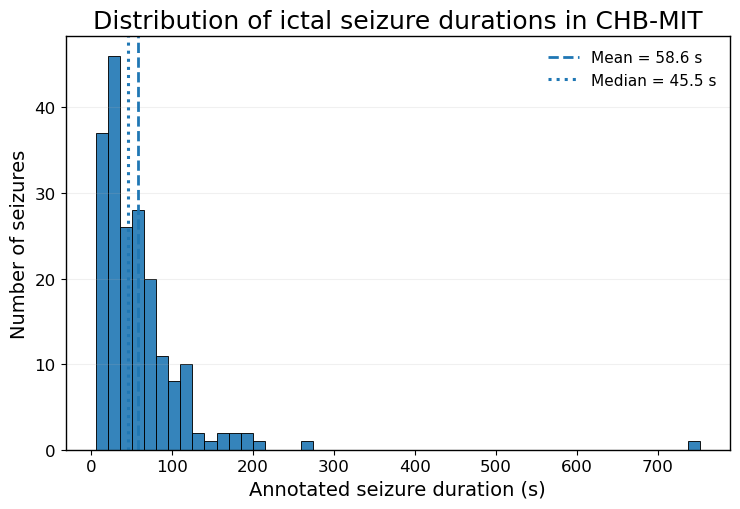

In [3]:
# ================================================================
# Manuscript-quality CHB-MIT seizure-duration distribution
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ictal/seizure duration distribution
ictal_dur = events_df["seizure_duration_sec"].dropna()
ictal_dur = ictal_dur[ictal_dur > 0]

mean_sec = ictal_dur.mean()
median_sec = ictal_dur.median()

print(f"Number of ictal events: {len(ictal_dur)}")
print(f"Mean ictal duration: {mean_sec:.2f} sec ({mean_sec/60:.2f} min)")
print(f"Median ictal duration: {median_sec:.2f} sec ({median_sec/60:.2f} min)")

# ------------------------------------------------
# Plot
# ------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 5.2))

ax.hist(
    ictal_dur,
    bins=50,
    edgecolor="black",
    linewidth=0.7,
    alpha=0.9
)

ax.axvline(
    mean_sec,
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_sec:.1f} s"
)

ax.axvline(
    median_sec,
    linestyle=":",
    linewidth=2.2,
    label=f"Median = {median_sec:.1f} s"
)

ax.set_xlabel(
    "Annotated seizure duration (s)",
    fontsize=14
)

ax.set_ylabel(
    "Number of seizures",
    fontsize=14
)

ax.tick_params(
    axis="both",
    labelsize=12
)

ax.legend(
    fontsize=11,
    frameon=False
)

ax.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8
)

plt.title("Distribution of ictal seizure durations in CHB-MIT", fontsize=18)

# ------------------------------------------------
# Keep full box around the plot
# ------------------------------------------------
for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.0)

fig.tight_layout()

# ------------------------------------------------
# Save manuscript-quality outputs
# ------------------------------------------------
fig.savefig(
    "chbmit_seizure_duration_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "chbmit_seizure_duration_distribution.pdf",
    bbox_inches="tight"
)

plt.show()